In [144]:
import sys
sys.path.insert(0, '..')

In [145]:
# Basic imports
import jax.numpy as np
import jax.random as jr
import jax.scipy as jsp
import jax
import numpy

jax.config.update("jax_enable_x64", True)


# Optimisation imports
import zodiax as zdx
import optax
import optimistix as optx

# dLux imports
import dLux as dl
import dLux.utils as dlu

# Visualisation imports
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib
import chainconsumer as cc


%matplotlib inline
plt.rcParams['image.cmap'] = 'inferno'
plt.rcParams["font.family"] = "serif"
plt.rcParams["image.origin"] = 'lower'
plt.rcParams['figure.dpi'] = 72
plt.rcParams["font.size"] = 24

from detectors import *
from apertures import *
from models import *
from stats import posterior
from fitting import *
from plotting import *
from spectra import *

import interpax as ipx


In [146]:
wf_wid = 512
wid = 80
oversample = 4

nwavels = 3
npoly=1

n_modes = 45
n_zernikes = 30

resolved_wid = 1

# Fresnel (ABCD) propagation through the occulter; defocus1/2 (occulter) and defocus3 (detector) are available
optics = NICMOSFresnelCoronagraph(wf_wid, wid, oversample, n_modes=n_modes, n_zernikes=n_zernikes, amplitude=True)

detector = NICMOSDetector(oversample, wid)

spectrum_basis = np.ones((nwavels, npoly))


ddir = '../data/NICMOS-LAPL-DD2/LAPL_DATA_DD2/comtemp_flats-DD2/'
# ddir = '../data/NICMOS-LAPL-DD1/archive.stsci.edu/missions/hlsp/laplace/dd1/LAPL/NICMOS-LAPL-DD1/LAPL_DATA/contemp_flats/repaired/'

flatdir = '../data/NICMOS-LAPL-DD2/LAPL_HOLEFLATS_DD2/'

# vects = np.load("../data/iterative_spectrum_basis_F160W.npy")[:,:npoly]
# assert vects.shape == (nwavels, npoly)
# spectrum_basis = vects/np.sqrt(np.mean(vects**2, axis=0))

# extra_bad = np.full((wid,wid), False).at[30:50, 30:50].set(True)#.at[:, 35:45].set(True)


# cold-mask OPD and defocus can differ between exposures; the rest of the cold-mask geometry stays global
class PerExposureOPDFit(SinglePointFit):
    PARAM_KEYS = SinglePointFit.PARAM_KEYS | {"cold_mask_opd": "exposure",
                                              "defocus3": "exposure"}

exposures_single = [
    exposure_from_file(ddir + 'n8jv51u6q_o_clc_calf.fits', PerExposureOPDFit(spectrum_basis, "F187N"), crop=wid, extra_bad=None, flatcorr=flatdir),
    # exposure_from_file(ddir + 'n8jv53xsq_o_clc_calf.fits', PerExposureOPDFit(spectrum_basis, "F187N"), crop=wid, extra_bad=None, flatcorr=flatdir),

    # exposure_from_file(ddir + 'n8zu85ndq_m_clc_calf.fits', SinglePointFit(spectrum_basis, "F160W"), crop=wid),
]


ADCZERO                    0.0 / analog-digital conversion zero level (DN)       [astropy.io.fits.card]


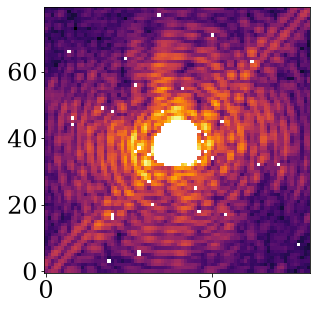

In [147]:
plt.imshow(exposures_single[0].data**0.125)

In [148]:
256-181,256-44

(75, 212)

In [149]:
exposures_single[0].hdr["TARSIAFY"]

211.546

In [150]:
# np.array([
#         256-181 - np.array(exp.hdr["TARSIAFX"],dtype=float), 
#         256-44 - np.array(exp.hdr["TARSIAFY"],dtype=float)
#     ])*0.075

In [151]:
exposures_single[0].target

'BD+032954'

In [152]:
(np.nansum(exposures_single[0].data)/nwavels)*4

Array(21522.14571681, dtype=float64)

In [153]:
params = {
    "spectrum": {},
    "primary_opd": {},
    "primary_amp": {},
    "primary_low": {},
    "primary_tilt": {},
    "cold_mask_opd": {},
    "cold_mask_tilt": {},
    "cold_mask_shift": {},
    "cold_mask_rot": {},
    "cold_mask_shear": {},
    "cold_mask_scale": {},
    "cold_mask_distortion": {},
    "primary_rot": {},
    "primary_shear": {},
    # "jitter": {},

    "bias": {},
    "occulter_radius": 0.8,
    "occulter_ellipticity": np.zeros(2),   # (e1, e2); major axis at atan2(e2, e1)/2 from the occulter-plane x axis
    "occulter_glint": np.zeros((5, 2)),   # (re, im) of a uniform edge ring; (3, 2) adds the first harmonic
    "occulter_glint_width": 3.,   # um in the occulter plane
    "fnumber": 45.7,
    "defocus1": {},
    "defocus2": {},
    "defocus3": {},
    "anisotropy": 1.+1e-5,

    "outer_radius": 1.2*0.9768,
    "secondary_radius": 0.365*1.2,
    "spider_width": 0.072*1.2,
    "primary_spider": 0.0256,
    "primary_secondary": 0.330*1.2,
    "secondary_shift": np.zeros(2),   # cm, spider-aligned frame; ~1 cm expected from the 7.4' field offset
    "primary_outer": 1.2,
    "primary_pad": 0.065*1.2,
    "primary_distortion": np.zeros((2, 7)),   # fraction of the 1.2 m radius at the edge
    "distortion": np.zeros((2, 7))
}


for idx, exp in enumerate(exposures_single):
    params["spectrum"][exp.fit.get_key(exp, "spectrum")] = (np.zeros(npoly)).at[0].set((np.nansum(exp.data)/nwavels)*210)

    params["primary_tilt"][exp.fit.get_key(exp, "primary_tilt")] = np.array([-0.05, -0.75])*0.075
    # params["cold_mask_tilt"][exp.fit.get_key(exp, "cold_mask_tilt")] = np.array([-0.2167105 , -0.17420508])#*0.
    params["cold_mask_tilt"][exp.fit.get_key(exp, "cold_mask_tilt")] = np.array([
        np.array(exp.hdr["TARSIAFY"],dtype=float) - (256-44),
        np.array(exp.hdr["TARSIAFX"],dtype=float) - (256-181), 
        # np.array(exp.hdr["TARSIAFY"],dtype=float) - (256-44)
    ])*0.075


    params["primary_opd"][exp.fit.get_key(exp, "primary_opd")] = np.zeros((n_modes, n_modes))
    params["primary_amp"][exp.fit.get_key(exp, "primary_amp")] = np.zeros((n_modes, n_modes))
    params["primary_low"][exp.fit.get_key(exp, "primary_low")] = np.zeros((n_zernikes))
    params["cold_mask_opd"][exp.fit.get_key(exp, "cold_mask_opd")] = np.zeros(16).at[0].set(120.)#np.array([120.])
    for k in ("defocus1", "defocus2", "defocus3"):
        params[k][exp.fit.get_key(exp, k)] = 0.
    params["cold_mask_distortion"][exp.fit.get_key(exp, "cold_mask_distortion")] = np.zeros((2, 7))

    params["cold_mask_shift"][exp.fit.get_key(exp, "cold_mask_shift")] = np.array([13.,10.]) #np.asarray([-13.,-7.])#
    params["cold_mask_rot"][exp.fit.get_key(exp, "cold_mask_rot")] = 3.2#-180
    params["primary_rot"][exp.fit.get_key(exp, "primary_rot")] = -0.6#-180
    params["cold_mask_scale"][exp.fit.get_key(exp, "cold_mask_scale")] = np.asarray([1.,1.])
    params["cold_mask_shear"][exp.fit.get_key(exp, "cold_mask_shear")] = np.asarray([0.06,-0.06])
    params["primary_shear"][exp.fit.get_key(exp, "primary_shear")] = np.asarray([0.,0.])

    params["bias"][exp.fit.get_key(exp, "bias")] = 0.
    # params["jitter"][exp.fit.get_key(exp, "jitter")] = 7. # mas; gradient vanishes at 0
    

model_single = set_array(NICMOSModel(exposures_single, params, optics, detector))

params = ModelParams(params)

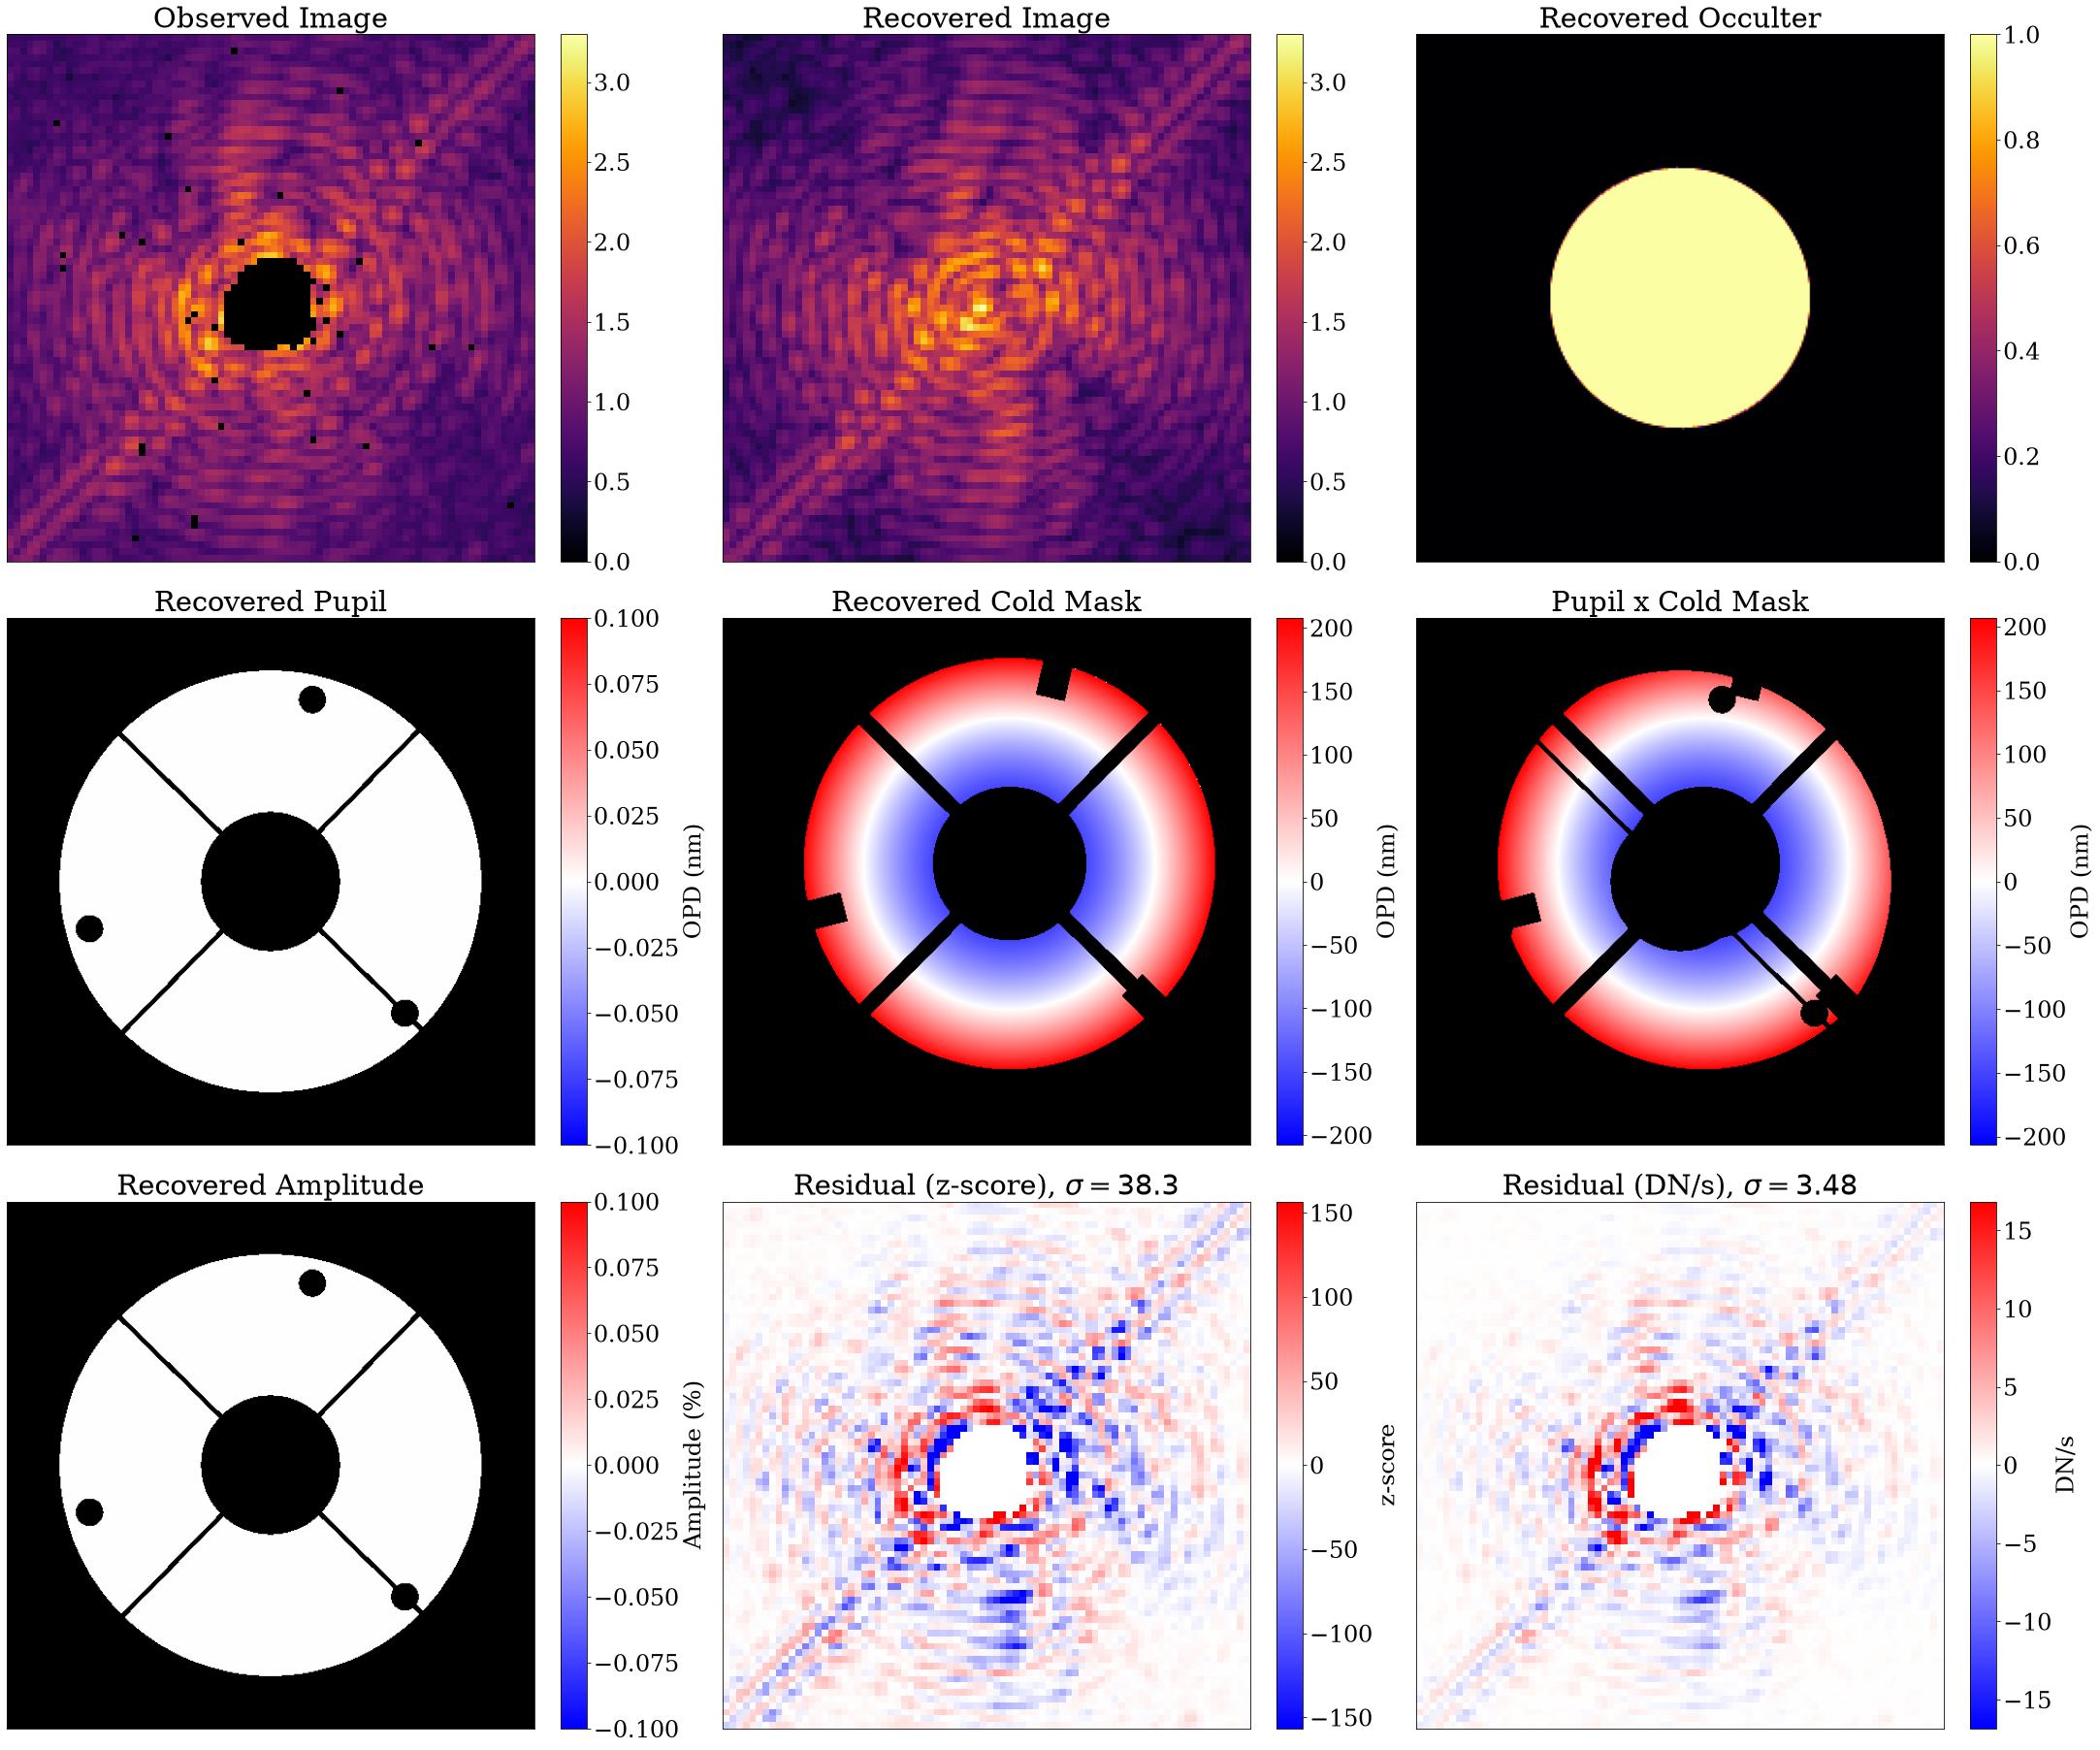

In [154]:
plot_comparison_detailed(model_single, params, exposures_single, percentile=99, wf_size=wf_wid)

In [155]:
# stop

In [156]:
g = 5e-2

things = {
    "primary_opd": adam(5e-2, 50),#sgd(g*2, 0),
    # Delayed until well after the phase (primary_opd starts at 50), so the phase is fitted first
    # and the phase/amplitude degeneracy is avoided
    "primary_amp": adam(5e-2, 500),

    "spectrum": sgd(g*1, 0),
    "primary_tilt": sgd(g*1., 0),
    "cold_mask_tilt": sgd(g*1, 0),
    "cold_mask_opd": sgd(g*1., 0),

    "defocus1": sgd(g*1, 0),
    "defocus2": sgd(g*1, 0),

    "bias": sgd(g*3, 0),
    "cold_mask_shift": sgd(g*1, 0),
    "cold_mask_rot": sgd(g*1., 0.),
    "primary_rot": sgd(g*3., 0),

    "primary_low": sgd(g*1, 0),
    # "jitter": sgd(g*1, 100),

    "cold_mask_scale": sgd(g*1, 0),
    "cold_mask_distortion": sgd(g*3, 0),
    # "cold_mask_shear": sgd(g*1, 0),

    # "primary_shear": sgd(g*1, 0),

    "occulter_radius": sgd(g*1., 0),
    "occulter_ellipticity": sgd(g*3, 300),
    "occulter_glint": sgd(g*15, 400),
    "occulter_glint_width": sgd(g*5, 600),   # smaller: width and amplitude trade off (ring area ~ g w)

    "outer_radius": sgd(g*1, 0),
    "secondary_radius": sgd(g*1, 0),
    "spider_width": sgd(g*1, 0),
    "primary_spider": sgd(g*1, 0),
    "primary_secondary": sgd(g*1, 0),
    "secondary_shift": sgd(g*1, 0),
    "primary_pad": sgd(g*1, 0),
    "primary_outer": sgd(g*1, 0),

    "fnumber": sgd(g*1., 0),
    "anisotropy": sgd(g*1., 0),
    "distortion": sgd(g*1, 0),
    "primary_distortion": sgd(g*3, 0),


}

things_start = {
    "spectrum": sgd(g*3, 30.),
    "primary_tilt": sgd(g*5., 15.),
    "cold_mask_tilt": sgd(g*1., 0),
    "cold_mask_opd": sgd(g*0.1, 40),

    "defocus1": sgd(g*1, 60),
    "defocus2": sgd(g*10, 60),

    "bias": sgd(g*3, 50),
    "cold_mask_shift": sgd(g*0.3, 70),
    "cold_mask_rot": sgd(g*0.1, 85),
    "primary_rot": sgd(g*0.03, 85),

    "primary_low": sgd(g*2., 150),

    # "cold_mask_scale": sgd(g*0.3, 100),
    "cold_mask_shear": sgd(g*0.1, 100),
    "cold_mask_distortion": sgd(g*0.1, 150),

    "primary_shear": sgd(g*1, 100),

    "occulter_radius": sgd(g*1., 120),
    "occulter_glint": sgd(g*0.1, 300),

    "outer_radius": sgd(g*0.1, 120),
    "secondary_radius": sgd(g*0.1, 120),
    "spider_width": sgd(g*0.1, 120),
    "primary_spider": sgd(g*0.1, 120),
    "primary_secondary": sgd(g*0.1, 120),
    "secondary_shift": sgd(g*0.3, 120),
    "primary_pad": sgd(g*0.1, 120),
    "primary_distortion": sgd(g*0.1, 150),
    "primary_outer": sgd(g*0.1, 120),
    "fnumber": sgd(g*1., 200),
    "anisotropy": sgd(g*2., 200),
}

groups = list(things.keys())

In [157]:
orig_params = params.params
opt_params = set_array({k:orig_params[k] for k in orig_params if k in things_start})

In [158]:
losses, params_history = optimise_new(
    opt_params, model_single, exposures_single, things_start, 500,
    precond_method="gn_exact", precond_kwargs=dict(chunk=16))

  0%|          | 0/500 [00:00<?, ?it/s]

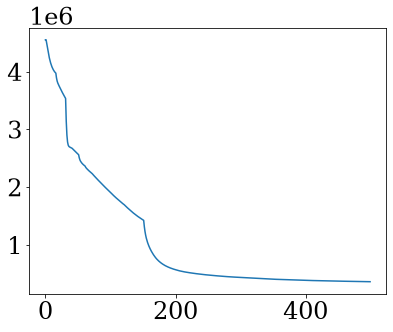

In [159]:
plt.plot(losses[:])

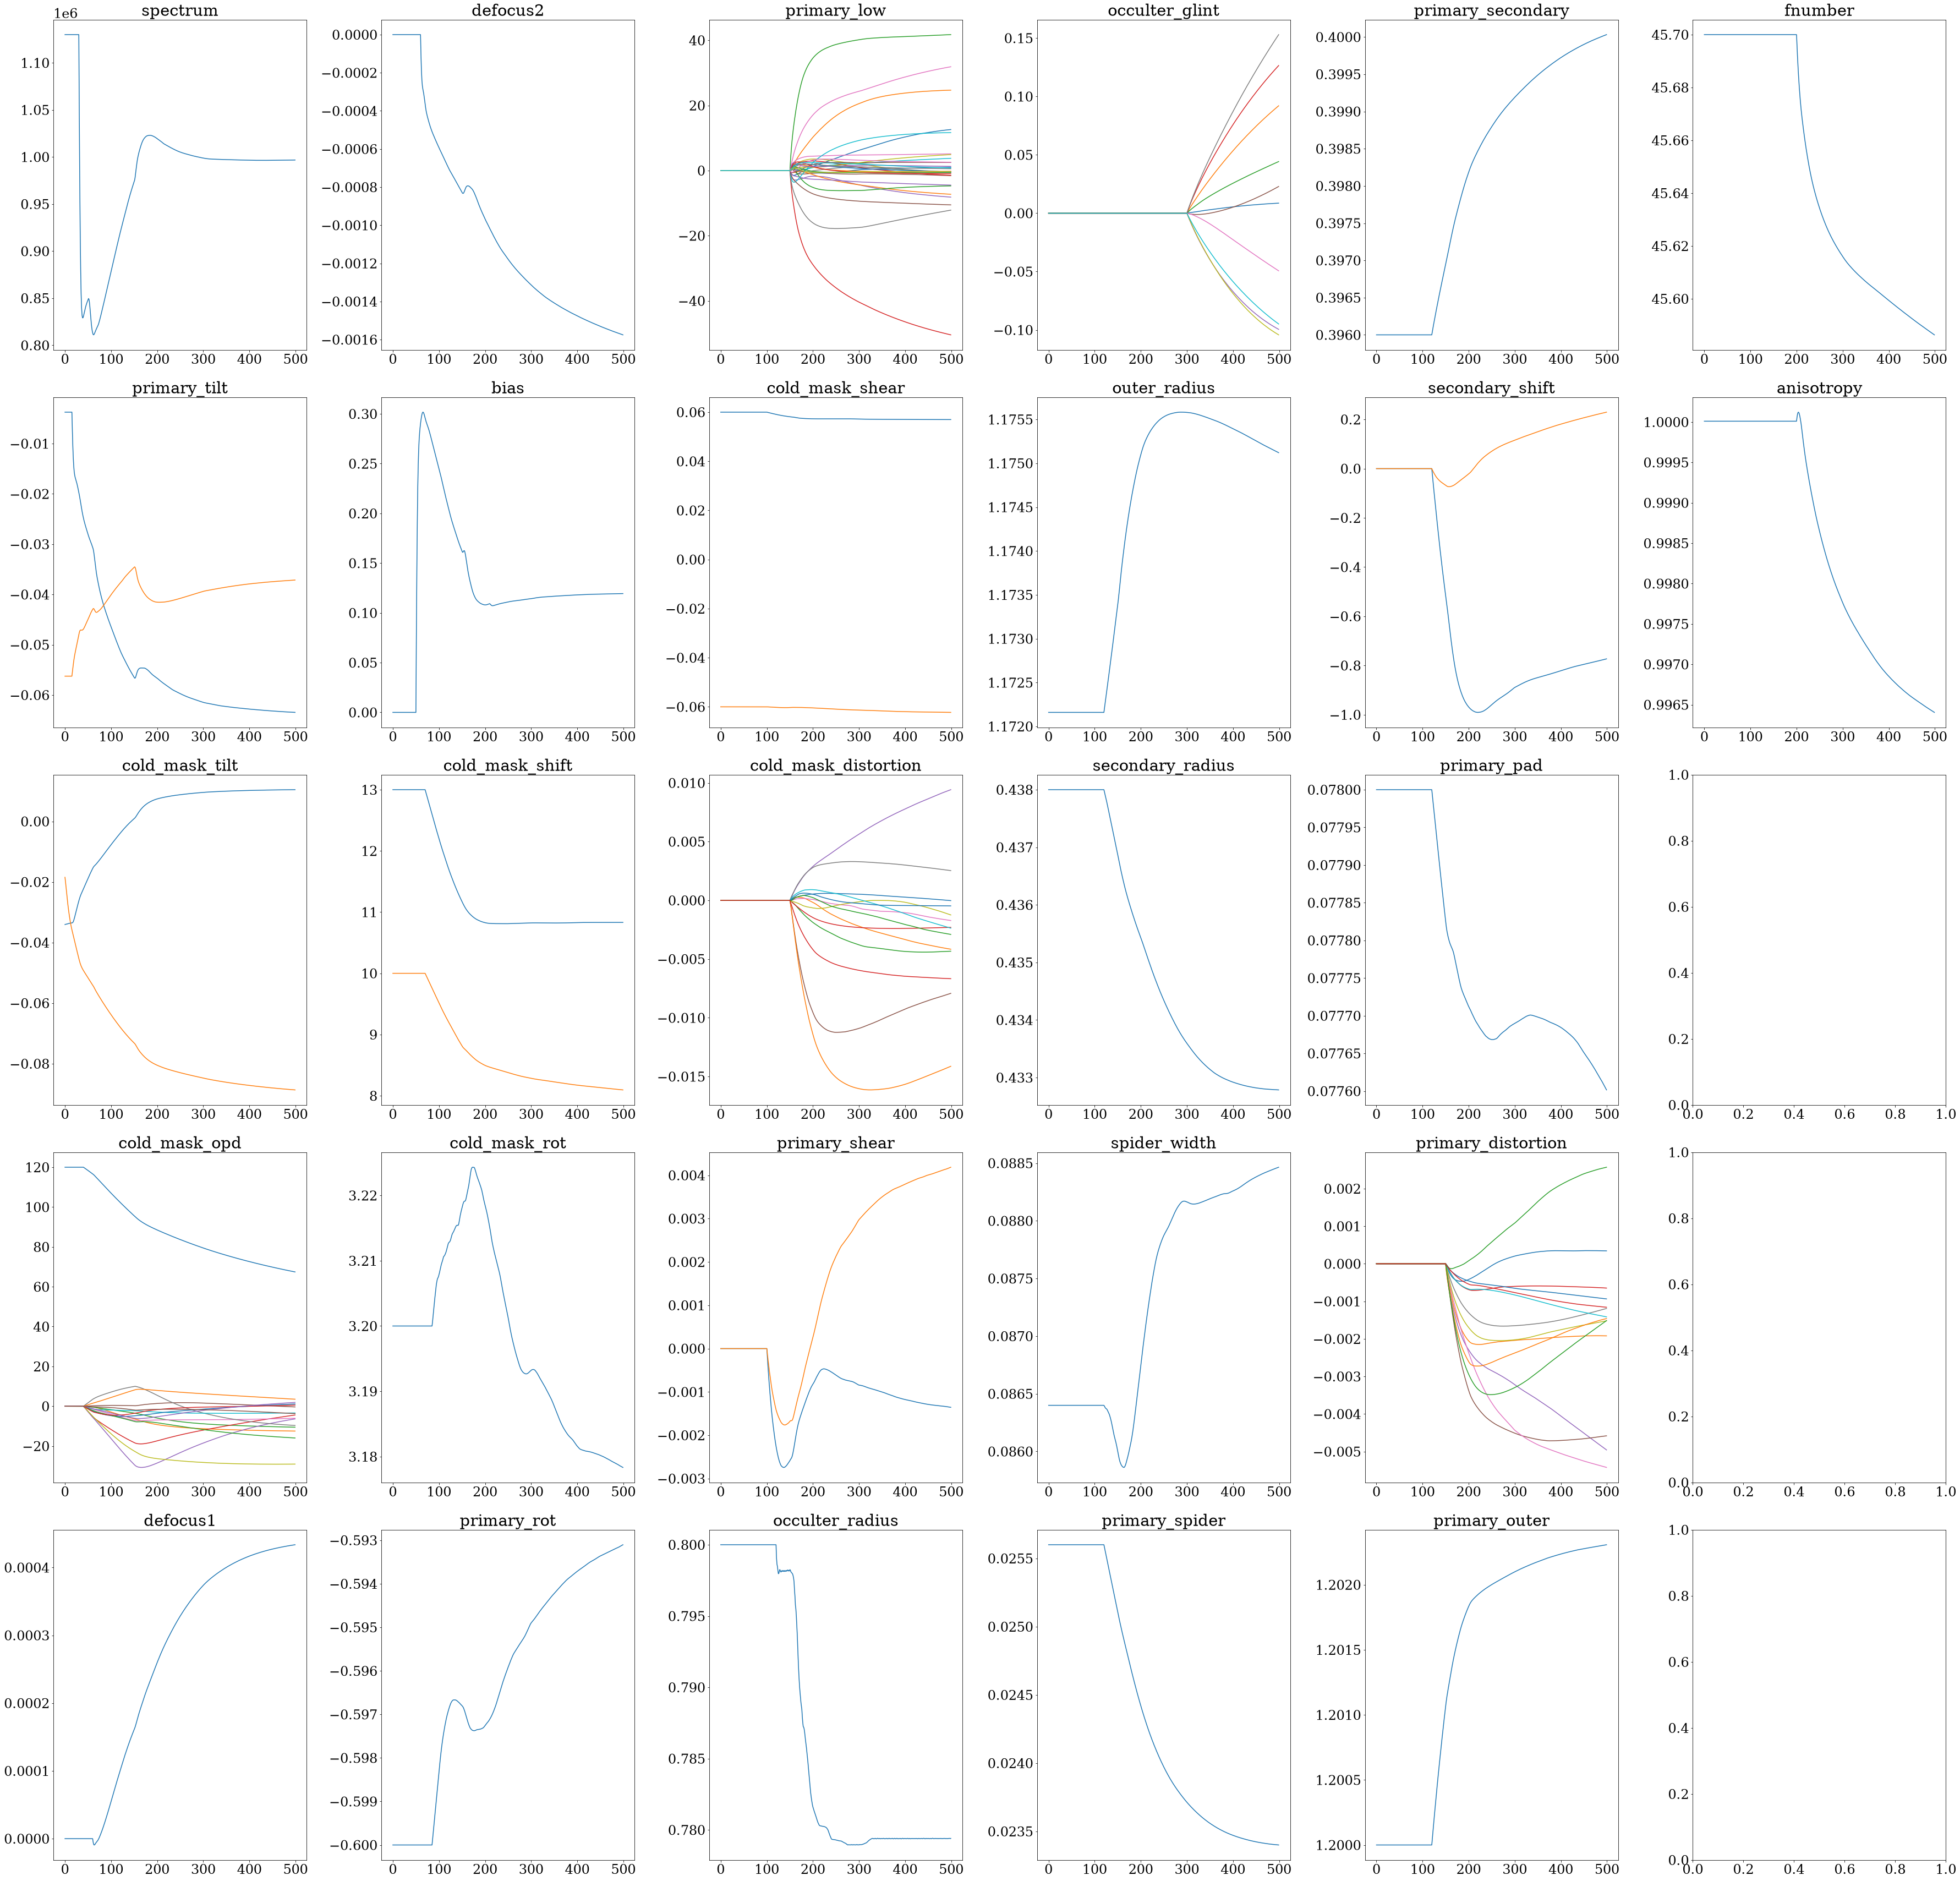

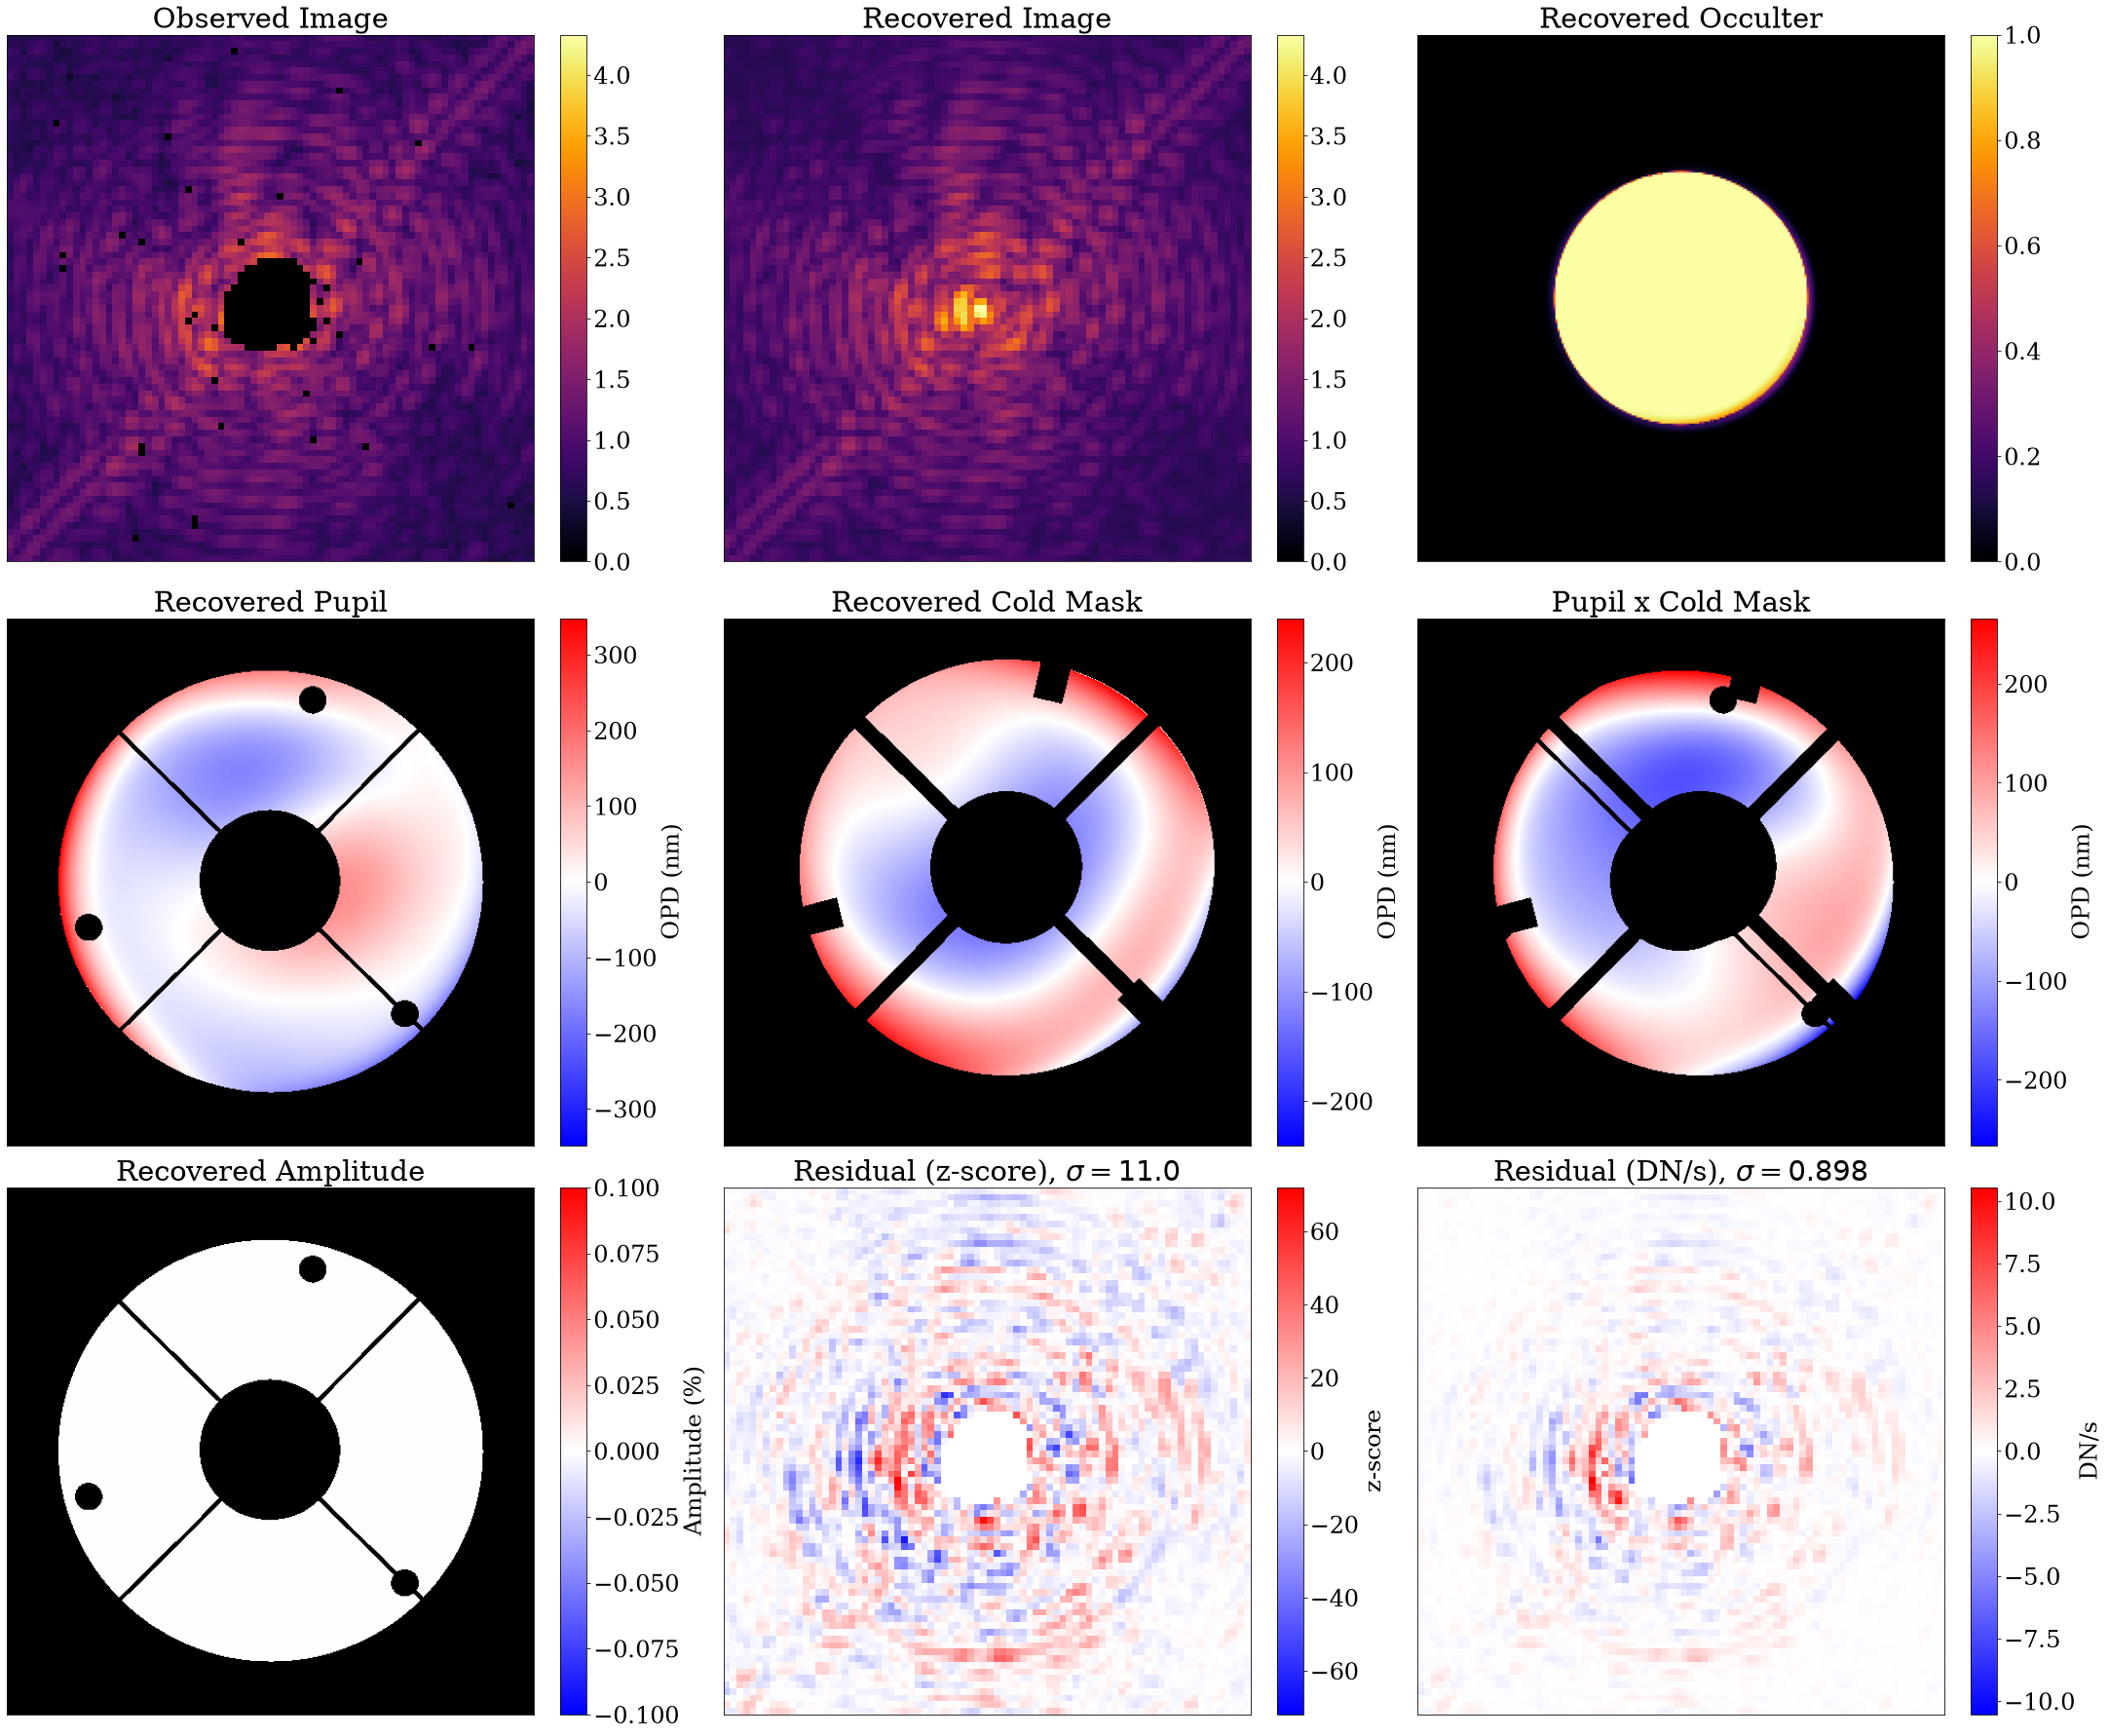

In [160]:
plot_params(params_history, list(things_start.keys()), xw = 5)
plot_comparison_detailed(model_single, ModelParams(params_history[-1]), exposures_single, percentile=100, quadrature=False, wf_size=wf_wid)

In [161]:
final_model = ModelParams(params_history[-1]).inject(model_single)
final_optics = exposures_single[0].fit.update_optics(final_model, exposures_single[0])

In [162]:
# best_params = ModelParams(params.params | params_history[-1])
# columns, jacobian = model_jacobian(model_single, best_params, exposures_single[0])
# plot_jacobian(columns, jacobian)

In [163]:
# Keep the stage-1 values of parameters that stage 2 does not fit (stage 2 injects into model_single)
model_single = ModelParams(params_history[-1]).inject(model_single)
orig_params = params.params | params_history[-1]
opt_params = set_array({k:orig_params[k] for k in orig_params if k in things})

In [164]:
losses, params_history = optimise_new(
    opt_params, model_single, exposures_single, things, 1000,
    precond_method="gn_probe", precond_kwargs=dict(n_probes=32))

  0%|          | 0/1000 [00:00<?, ?it/s]

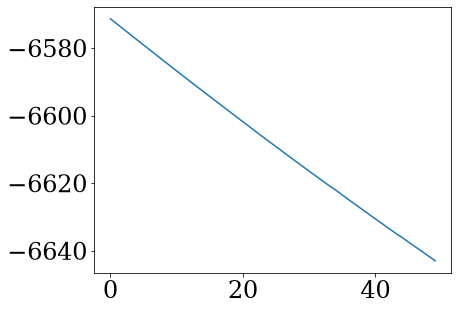

In [165]:
plt.plot(losses[-50:])

In [166]:
losses[-1]

np.float64(-6642.968111097427)

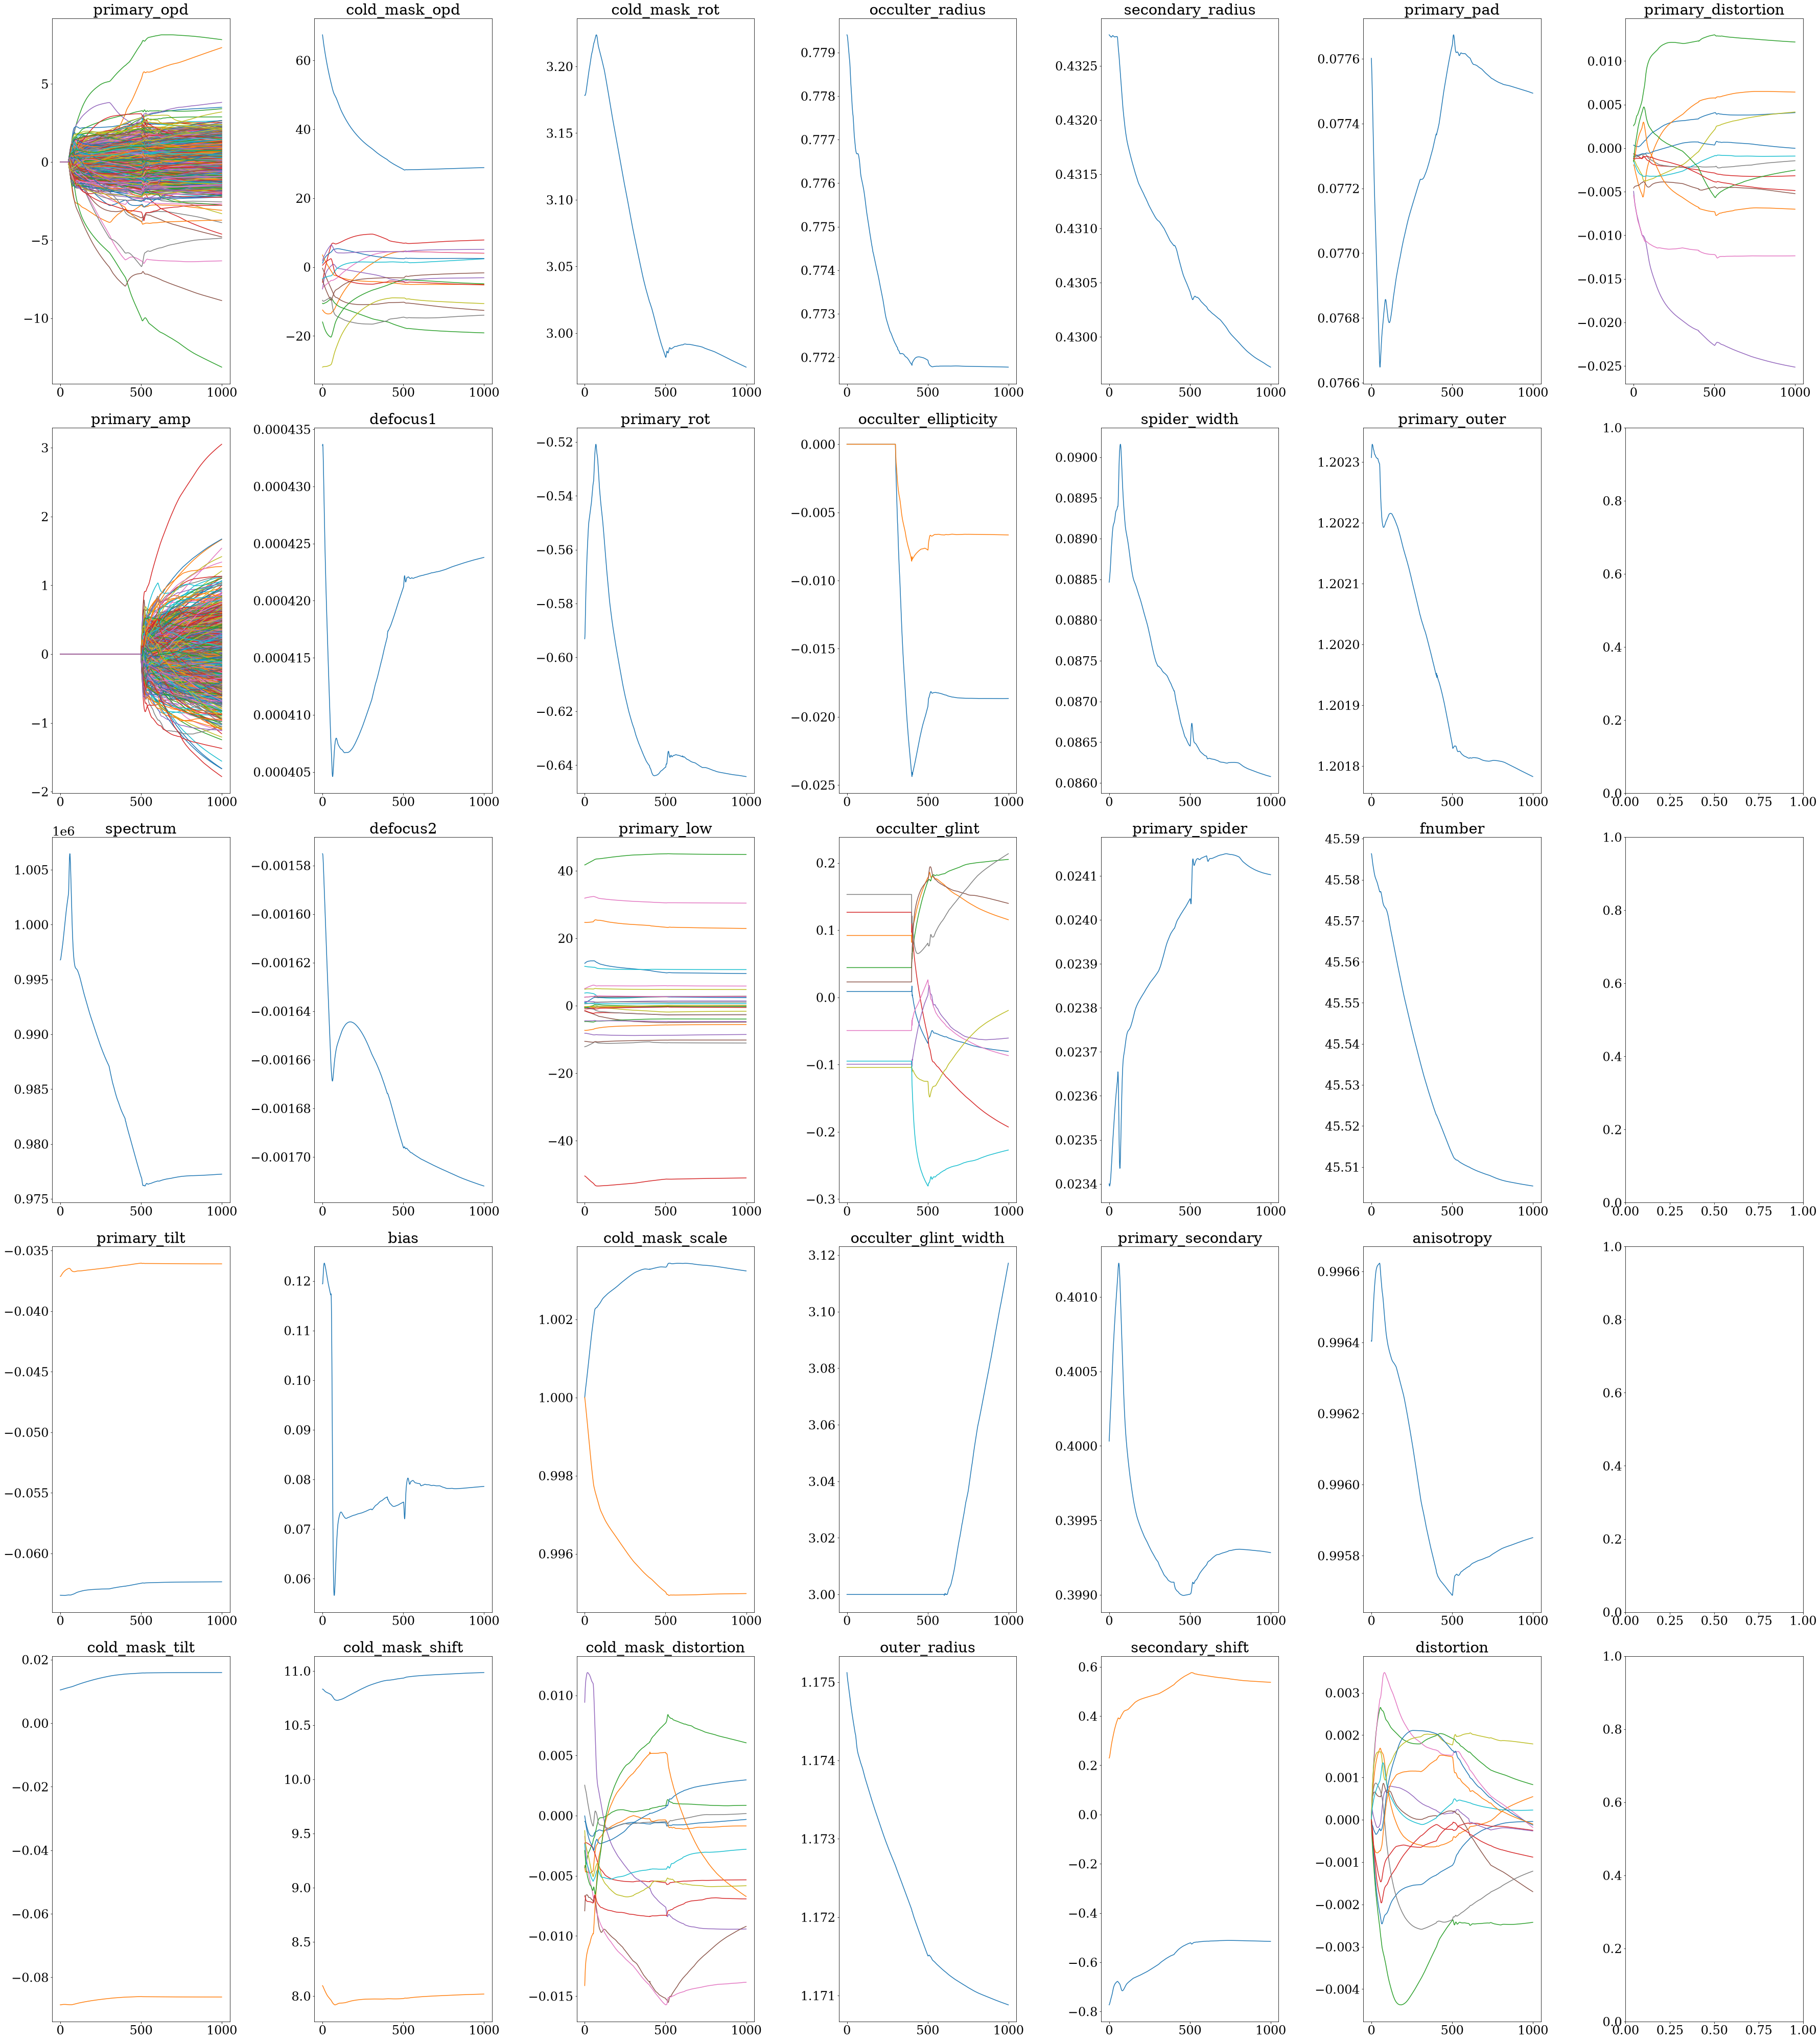

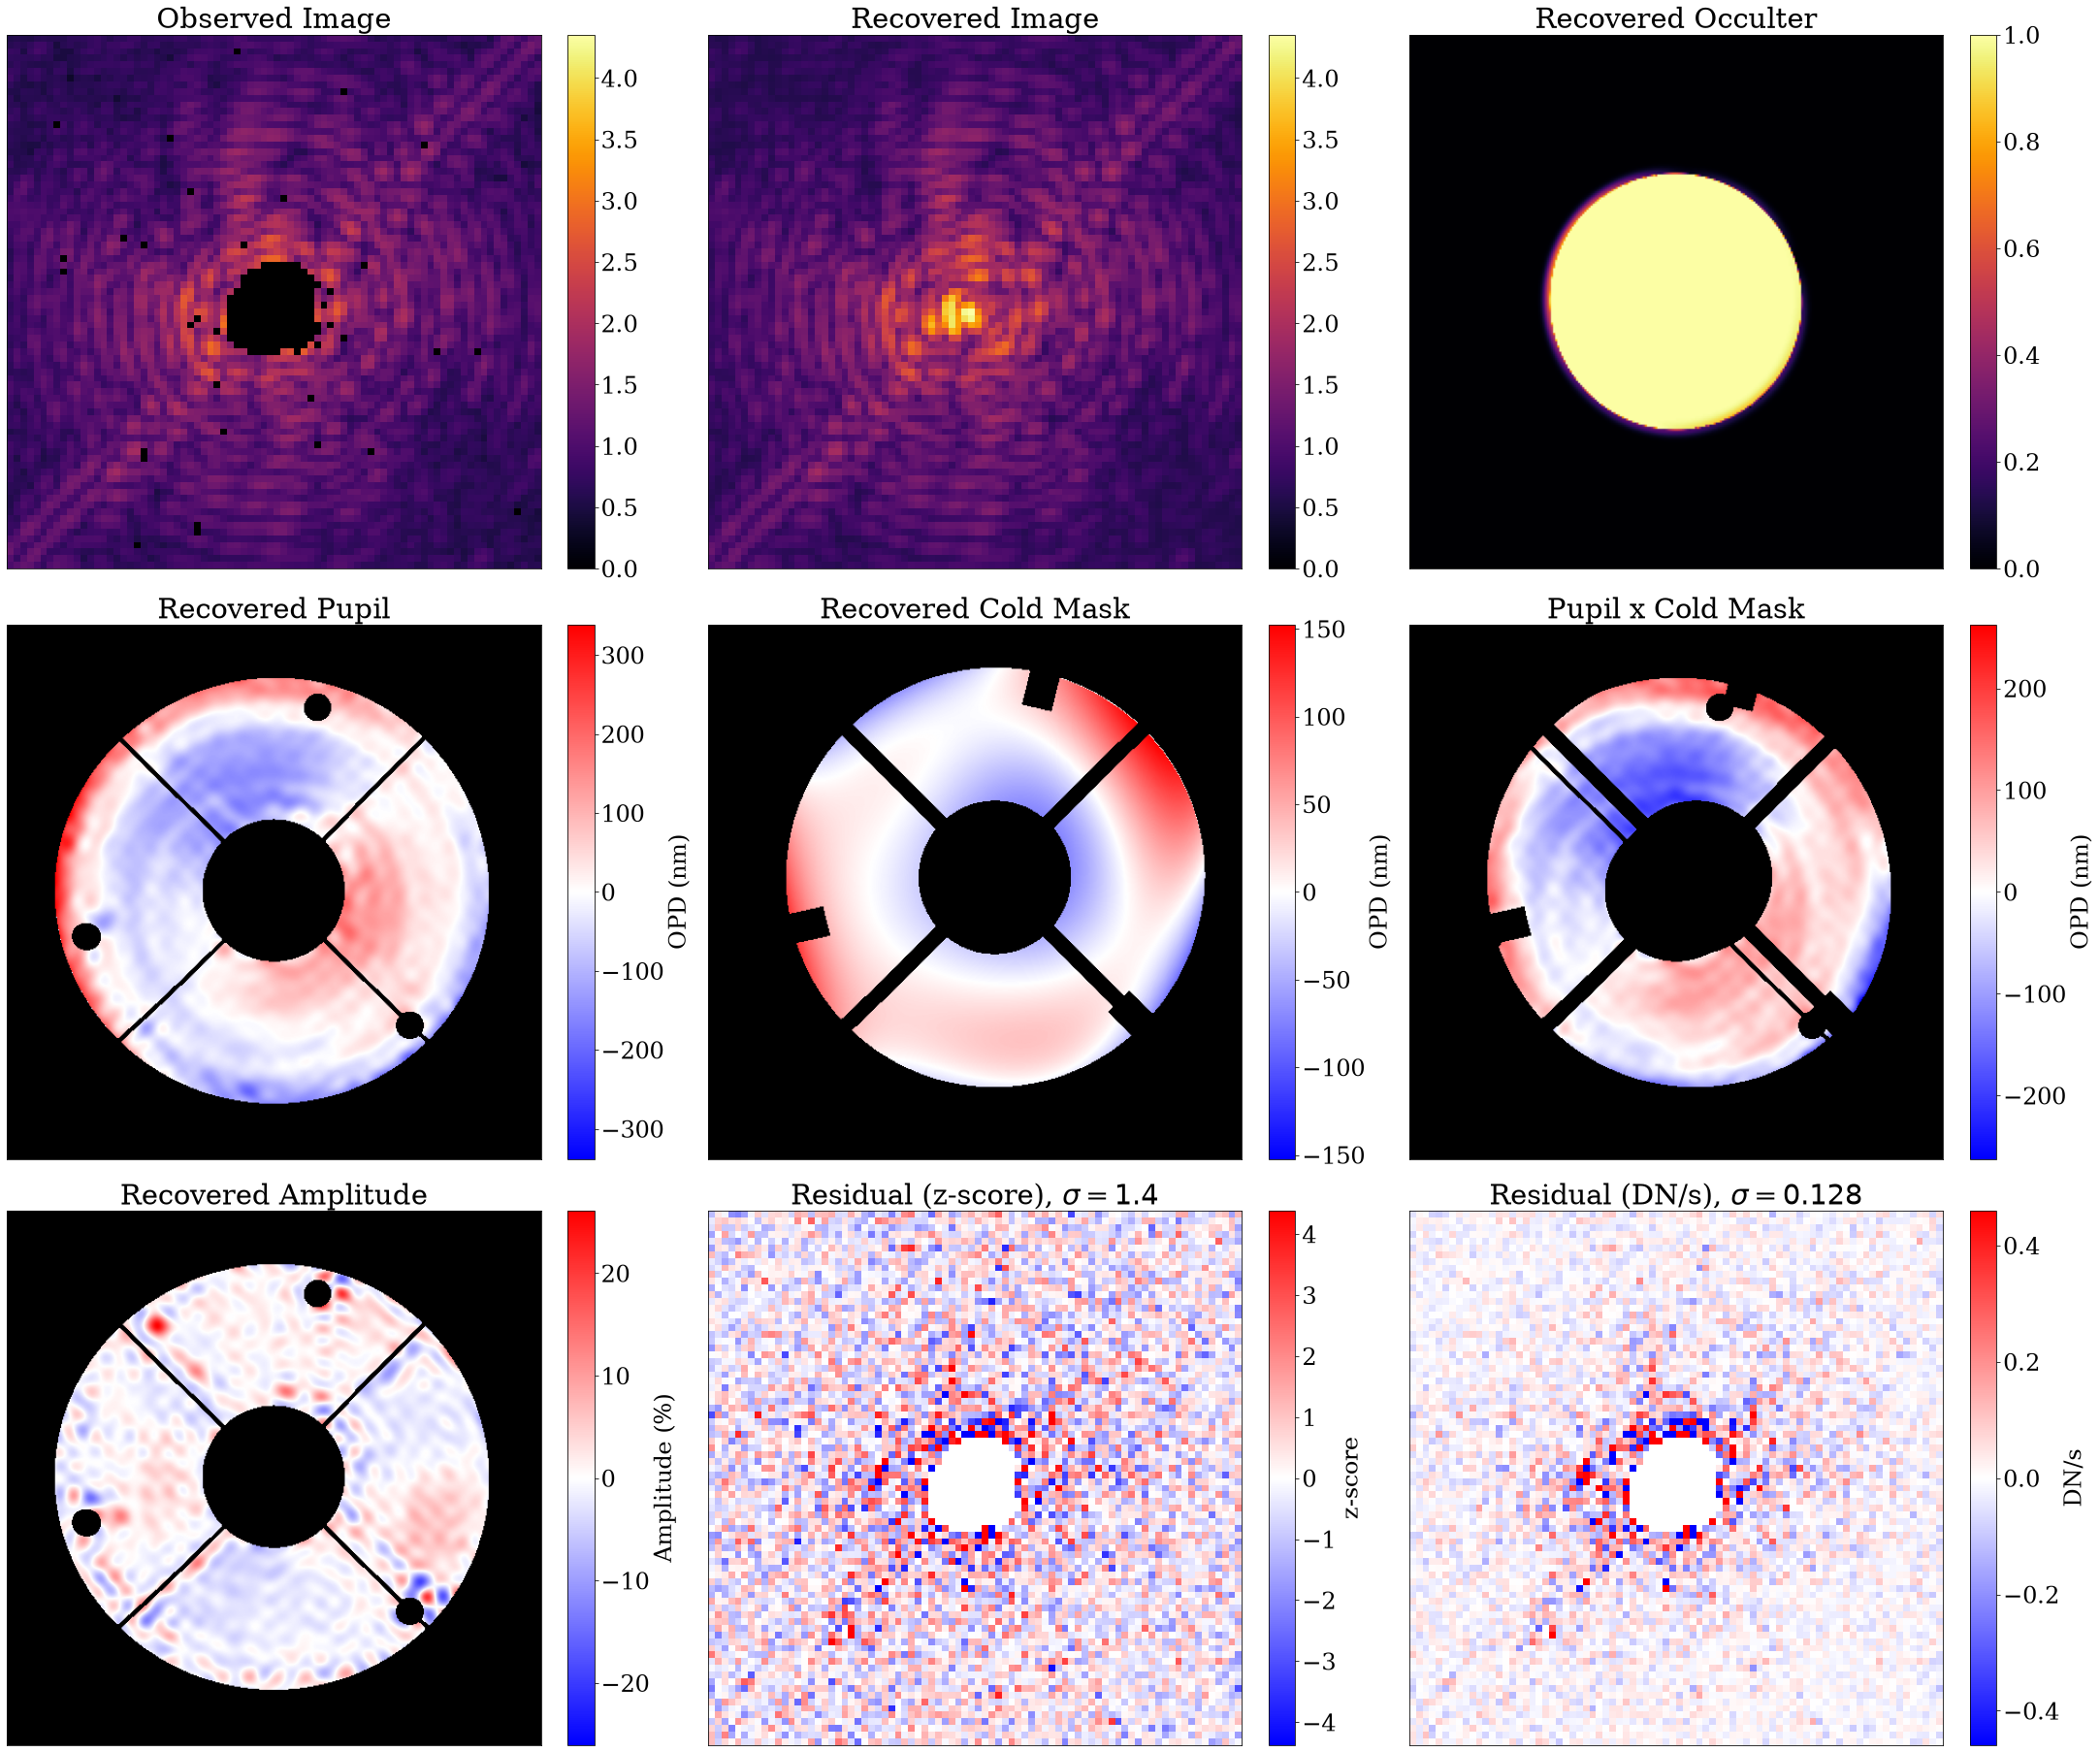

In [167]:
plot_params(params_history, groups, xw = 5)
plot_comparison_detailed(model_single, ModelParams(params_history[-1]), exposures_single, quadrature=False, wf_size=wf_wid, percentile=99)

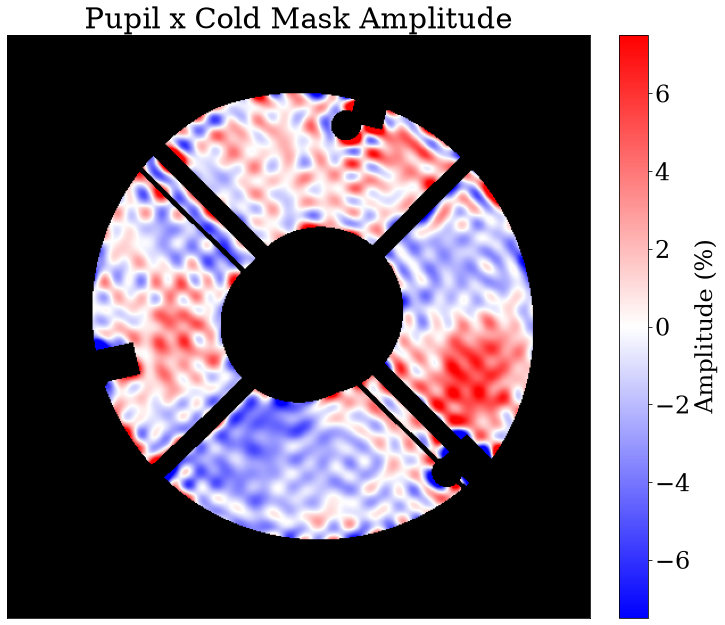

In [168]:
from plotting import _signed_panel  # underscore names are not covered by `import *`

# Recovered amplitude where both the primary and the cold mask transmit, as in "Pupil x Cold Mask"
model = ModelParams(params_history[-1]).inject(model_single)
exp = exposures_single[0]
optics = exp.fit.update_optics(model, exp)

coords = dlu.pixel_coords(wf_wid, optics.diameter)
primary = optics.primary.transmission(coords, 2.4/wf_wid)
cold_mask = optics.cold_mask.transmission(coords, 2.4/wf_wid)
amp = 100*(np.exp(optics.primary_amp.eval_basis()) - 1)

fig, ax = plt.subplots(figsize=(10, 10), layout='compressed')
_signed_panel(ax, np.where(primary*cold_mask < .5, np.nan, amp), "Pupil x Cold Mask Amplitude", label="Amplitude (%)", percentile=99)


In [169]:
# Separate file: params.npy is loaded by notebooks whose optics have no primary_amp layer
np.save("params_amp_fresnel.npy", params_history[-1])
# print({k: float(np.abs(v)) for k, v in ModelParams(params_history[-1]).get("jitter").items()}, "mas")

In [170]:
# best_params = ModelParams(params.params | params_history[-1])
# columns, jacobian = model_jacobian(model_single, best_params, exposures_single[0])
# plot_jacobian(columns, jacobian)